# Week 5 · Class 2 — Inference & A/B Testing in Python 🔬📈

**90 min · hands-on** · tools: `numpy`, `pandas`, `matplotlib`, `scipy.stats`, `statsmodels`

Tuesday we went from a **model to data** (probability). Today we go from **data back to the world** (inference): how much can a sample tell us, and when is a difference real?
As on Tuesday, every idea is checked with a **simulation** first, then used on **data**.

| Part | Time | What we do |
|---|---|---|
| 0 | 3' | Setup |
| 1 | 10' | Sample vs population: why estimates vary |
| 2 | 12' | The central limit theorem |
| 3 | 8' | Standard error and the √n law |
| 4 | 12' | Confidence intervals |
| 5 | 15' | Hypothesis tests: one-sample, two groups, paired |
| 6 | 10' | Errors and power |
| 7 | 15' | A/B testing end to end |
| 8 | 5' | Final challenge + recap |

🧑‍💻 = we write it **together** · ✋ **Your turn** = 2–3 minutes on your own, then we compare.

### 📂 Datasets used in this notebook
| File | What it is | Used in |
|---|---|---|
| `wearables_daily.csv` | same file as Tuesday and Week 3: 250 users × 365 days = **91,250 user-days** (steps, sleep, resting heart rate, device, age group…) | Parts 1–6 |
| `blood_pressure.csv` | **100 patients**, blood pressure `before` and `after` a treatment | Part 5 (paired test) |
| `ab_test.csv` | **50 users per version**, minutes spent on a page with version `a` and version `b` | Part 7 (A/B test on means) |
| *(simulated)* | a conversion A/B test with 10,000 users per group, generated with numpy | Parts 6–7 |

📁 **Before running:** put the three CSV files next to this notebook.
- **Colab:** click the folder icon on the left and drag the files in (they are deleted when the session ends, so upload them again next time). `statsmodels` is already installed in Colab.
- **VS Code / Jupyter:** keep the files in the same folder as the notebook, and install statsmodels once with `uv add statsmodels`.

## 0 · Setup ⚙️

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

rng = np.random.default_rng(42)

In [2]:
df = pd.read_csv("wearables_daily.csv", parse_dates=["date"])
data = df[df["steps"] < 60_000].dropna(subset=["sleep_hours"]).copy()   # same cleaning as Tuesday

bp = pd.read_csv("blood_pressure.csv")
ab = pd.read_csv("ab_test.csv")

print("wearables:", data.shape, "| blood pressure:", bp.shape, "| ab_test:", ab.shape)

wearables: (88456, 17) | blood pressure: (100, 2) | ab_test: (50, 2)


---
## 1 · Sample vs population: why estimates vary 🎯 (10')

In real life we never see the whole population. Here we **cheat on purpose**: we treat all 88,000 user-days as the **population**, so we know the true answer and can check how good a small sample is.

| | Population (unknown in real life) | Sample (what we see) |
|---|---|---|
| mean | μ | x̄ |
| std | σ | s |

In [3]:
population = data["resting_hr"].to_numpy()
mu, sigma = population.mean(), population.std(ddof=0)
print(f"TRUE population: μ = {mu:.2f} bpm, σ = {sigma:.2f} bpm")

TRUE population: μ = 71.73 bpm, σ = 5.24 bpm


🧑‍💻 **Code with me:** take 5 different random samples of 25 user-days. Do we get the same mean?

In [4]:
for i in range(5):
    sample = rng.choice(population, size=25, replace=False)
    print(f"sample {i + 1}: x̄ = {sample.mean():.2f}   s = {sample.std(ddof=1):.2f}")

sample 1: x̄ = 74.12   s = 4.51
sample 2: x̄ = 73.44   s = 4.49
sample 3: x̄ = 71.00   s = 5.02
sample 4: x̄ = 74.08   s = 5.21
sample 5: x̄ = 72.60   s = 4.08


Every sample gives a **different** x̄. That's not a mistake: it's **sampling variability**. Inference is about measuring it.

### What if the sample is biased?
Suppose we only survey users aged 20–29 (it was easier to reach them). Even a **huge** sample won't fix that.

In [5]:
young = data.loc[data["age_group"] == "20-29", "resting_hr"]
print(f"young users only: x̄ = {young.mean():.2f} bpm with n = {len(young):,}")
print(f"true μ          : {mu:.2f} bpm")

young users only: x̄ = 69.39 bpm with n = 19,453
true μ          : 71.73 bpm


> ⚠️ A big biased sample gives a **precise wrong answer**. Random sampling matters more than sample size.

---
## 2 · The central limit theorem 🔔 (12')

`steps` is clearly **not** Normal: most days are moderate and a few are very active (right-skewed).

skewness of steps = 1.49  (0 = symmetric)


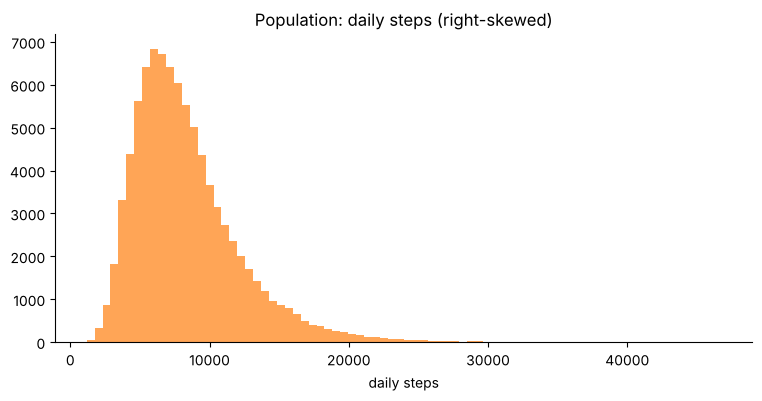

In [6]:
steps = data["steps"].to_numpy()
print(f"skewness of steps = {stats.skew(steps):.2f}  (0 = symmetric)")
plt.hist(steps, bins=80, color="tab:orange", alpha=0.7)
plt.xlabel("daily steps"); plt.title("Population: daily steps (right-skewed)"); plt.show()

🧑‍💻 **Code with me:** draw 10,000 samples of size n, compute each mean, and look at the histogram of the means for n = 2, 10 and 50.

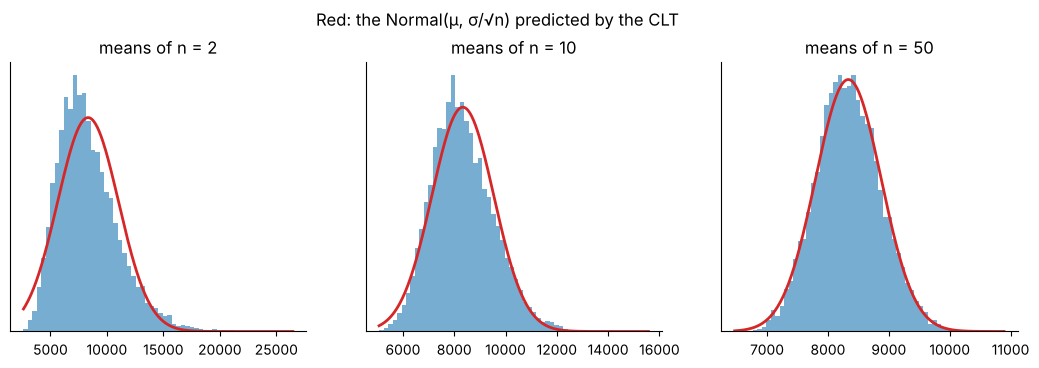

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, n in zip(axes, [2, 10, 50]):
    means = rng.choice(steps, size=(10_000, n)).mean(axis=1)     # 10,000 rows, one sample per row → one mean per row
    ax.hist(means, bins=60, density=True, alpha=0.6)
    grid = np.linspace(means.min(), means.max(), 300)
    ax.plot(grid, stats.norm.pdf(grid, steps.mean(), steps.std() / np.sqrt(n)), color="tab:red", lw=2)
    ax.set_title(f"means of n = {n}"); ax.set_yticks([])
plt.suptitle("Red: the Normal(μ, σ/√n) predicted by the CLT", y=1.03); plt.show()

With n = 2 the means are still skewed; with n = 50 they look Normal, and the red curve predicted by the CLT fits.

$$\bar{x} \approx \mathrm{Normal}\left(\mu,\ \frac{\sigma}{\sqrt{n}}\right) \quad \text{for } n \text{ large enough}$$

✋ **Your turn (2'):** use a **QQ plot** (Week 3!) to compare the raw steps and the means of n = 50 with a Normal.

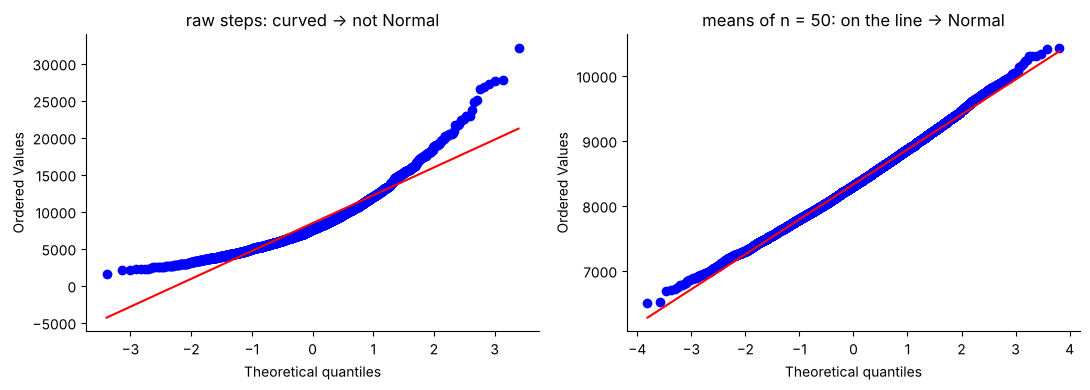

In [8]:
means50 = rng.choice(steps, size=(10_000, 50)).mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(rng.choice(steps, 2_000), dist="norm", plot=axes[0]); axes[0].set_title("raw steps: curved → not Normal")
stats.probplot(means50, dist="norm", plot=axes[1]); axes[1].set_title("means of n = 50: on the line → Normal")
plt.tight_layout(); plt.show()

---
## 3 · Standard error and the √n law 📏 (8')

The **standard error** is the std of the sampling distribution: how far x̄ typically lands from μ.

$$\mathrm{SE} = \frac{\sigma}{\sqrt{n}} \approx \frac{s}{\sqrt{n}}$$

In [9]:
for n in [25, 100, 400]:
    means = rng.choice(population, size=(20_000, n)).mean(axis=1)
    print(f"n = {n:>3}: std of 20,000 means = {means.std():.3f}   |   σ/√n = {sigma / np.sqrt(n):.3f}")

n =  25: std of 20,000 means = 1.039   |   σ/√n = 1.048
n = 100: std of 20,000 means = 0.525   |   σ/√n = 0.524
n = 400: std of 20,000 means = 0.261   |   σ/√n = 0.262


📌 Each time n is multiplied by **4**, the SE is **halved**. Precision gets expensive fast.

In practice we have **one** sample and estimate the SE from it:

In [10]:
sample = rng.choice(population, size=100, replace=False)
print("by hand   :", round(sample.std(ddof=1) / np.sqrt(len(sample)), 3))
print("stats.sem :", round(stats.sem(sample), 3))     # sem = standard error of the mean (uses ddof=1)

by hand   : 0.521
stats.sem : 0.521


> 🧠 **s vs SE:** `s` describes how different **individuals** are (≈ 5 bpm). `SE` describes how precise our **estimate** is (≈ 0.5 bpm with n = 100).

---
## 4 · Confidence intervals 📐 (12')

$$\text{95\% CI} = \bar{x} \pm t^{*}\cdot\frac{s}{\sqrt{n}} \qquad (t^{*} \approx 1.96 \text{ for large } n)$$

🧑‍💻 **Code with me:** a 95% CI for the mean resting heart rate from a sample of 50 user-days. By hand, then with scipy.

In [11]:
sample = rng.choice(population, size=50, replace=False)
x_bar, se = sample.mean(), stats.sem(sample)
t_star = stats.t.ppf(0.975, df=len(sample) - 1)       # t with n − 1 degrees of freedom (n − 1 again!)

print(f"x̄ = {x_bar:.2f}, SE = {se:.3f}, t* = {t_star:.3f}")
print(f"by hand : [{x_bar - t_star * se:.2f}, {x_bar + t_star * se:.2f}]")
print("scipy   :", np.round(stats.t.interval(0.95, df=len(sample) - 1, loc=x_bar, scale=se), 2))
print(f"true μ  : {mu:.2f}")

x̄ = 71.26, SE = 0.669, t* = 2.010
by hand : [69.91, 72.61]
scipy   : [69.91 72.61]
true μ  : 71.73


### What does 95% mean? Build 100 intervals and count how many contain the true μ.

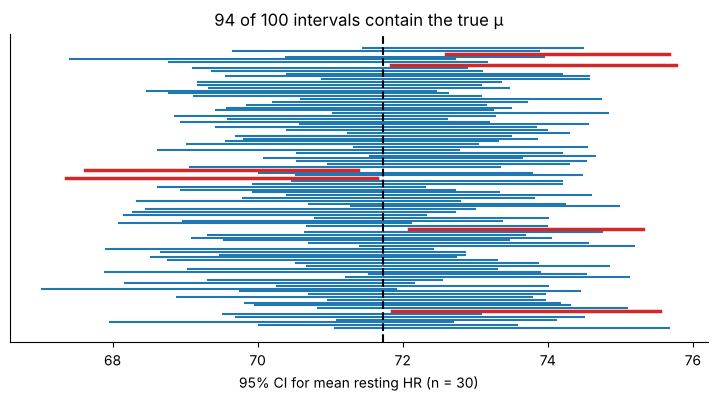

In [12]:
def ci_95(x):
    return stats.t.interval(0.95, df=len(x) - 1, loc=x.mean(), scale=stats.sem(x))

hits = 0
for i in range(100):
    low, high = ci_95(rng.choice(population, size=30, replace=False))
    ok = low <= mu <= high
    hits += ok
    plt.plot([low, high], [i, i], color="tab:blue" if ok else "tab:red", lw=1.5 if ok else 2.5)
plt.axvline(mu, color="black", ls="--")
plt.yticks([]); plt.xlabel("95% CI for mean resting HR (n = 30)")
plt.title(f"{hits} of 100 intervals contain the true μ"); plt.show()

📌 The **method** is right about 95% of the time. Any single interval either contains μ or not; the red ones are unlucky samples.

### CI for a proportion: share of days hitting the 10,000-step goal
$$\hat{p} \pm 1.96\sqrt{\frac{\hat{p}(1-\hat{p})}{n}}$$

In [13]:
goal = (data["steps"] >= 10_000).to_numpy()
p_true = goal.mean()

s = rng.choice(goal, size=400, replace=False)
p_hat = s.mean()
half = 1.96 * np.sqrt(p_hat * (1 - p_hat) / len(s))
print(f"p̂ = {p_hat:.3f} → 95% CI [{p_hat - half:.3f}, {p_hat + half:.3f}]   (true p = {p_true:.3f})")
print("does the interval contain the true p?", p_hat - half <= p_true <= p_hat + half)

p̂ = 0.312 → 95% CI [0.267, 0.358]   (true p = 0.259)
does the interval contain the true p? False


> 🎲 If your interval misses the true p, you just met one of the 5%! Run the cell again a few times: about 19 out of 20 intervals contain it.

✋ **Your turn (3'):** how does the width of the 95% CI for the mean resting HR change with n? Compute it for n = 25, 100, 400, 1600. What pattern do you see?

In [14]:
for n in [25, 100, 400, 1600]:
    low, high = ci_95(rng.choice(population, size=n, replace=False))
    print(f"n = {n:>4}: width = {high - low:.2f} bpm")
# pattern: 4× more data → about half the width (the √n law again)

n =   25: width = 4.93 bpm
n =  100: width = 2.36 bpm
n =  400: width = 1.10 bpm
n = 1600: width = 0.51 bpm


---
## 5 · Hypothesis tests ⚖️ (15')

The recipe: **(1)** state H₀ and H₁ · **(2)** pick α = 0.05 · **(3)** compute a test statistic · **(4)** p-value → decide.

### 5.1 One-sample t-test: is the average still 8,000 steps?
The product team claims a new onboarding changed daily steps, compared with the historical 8,000. We look at a random sample of 400 user-days.
H₀: μ = 8,000 · H₁: μ ≠ 8,000.

In [15]:
sample_steps = rng.choice(steps, size=400, replace=False)
x_bar, se = sample_steps.mean(), stats.sem(sample_steps)

t_stat = (x_bar - 8_000) / se                                       # how many SEs away from H₀?
p_value = 2 * stats.t.sf(abs(t_stat), df=len(sample_steps) - 1)     # two-sided: both tails
print(f"x̄ = {x_bar:,.0f}, SE = {se:.0f} → t = {t_stat:.2f}, p = {p_value:.4f}")

print(stats.ttest_1samp(sample_steps, popmean=8_000))              # same result in one line

x̄ = 8,382, SE = 177 → t = 2.16, p = 0.0316


TtestResult(statistic=np.float64(2.1574492343011094), pvalue=np.float64(0.031567038938400106), df=np.int64(399))


### What is a p-value, really? Simulate a world where H₀ is true
We shift the population so its mean is **exactly 8,000** (H₀ true), draw 10,000 samples of 400, and count how often the mean is at least as far from 8,000 as ours.

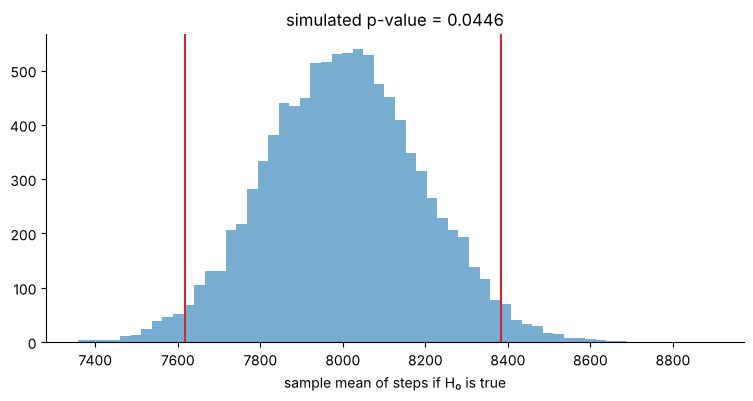

In [16]:
null_population = steps - steps.mean() + 8_000          # same shape, mean forced to 8,000
null_means = rng.choice(null_population, size=(10_000, 400)).mean(axis=1)

observed_gap = abs(x_bar - 8_000)
p_sim = np.mean(np.abs(null_means - 8_000) >= observed_gap)

plt.hist(null_means, bins=60, alpha=0.6)
plt.axvline(8_000 + observed_gap, color="tab:red"); plt.axvline(8_000 - observed_gap, color="tab:red")
plt.xlabel("sample mean of steps if H₀ is true"); plt.title(f"simulated p-value = {p_sim:.4f}"); plt.show()

📌 The p-value = how often **chance alone** (H₀ true) produces a result at least as extreme as ours. It is **not** the probability that H₀ is true.

✋ **Your turn (2'):** the true mean of our population is about 8,370 steps, so here H₀ is actually false. Repeat the test with samples of **n = 50** and **n = 2,000**. What happens to the p-value, and why?

In [17]:
for n in [50, 2_000]:
    s_n = rng.choice(steps, size=n, replace=False)
    print(f"n = {n:>5}: x̄ = {s_n.mean():,.0f}, p = {stats.ttest_1samp(s_n, 8_000).pvalue:.4f}")
# small n → low power: a real difference can easily give a large p.
# large n → the same difference becomes clearly significant.

n =    50: x̄ = 7,497, p = 0.3481
n =  2000: x̄ = 8,332, p = 0.0001


### 5.2 Two independent groups: do Apple Watch users sleep more than Fitbit users?
We use **Welch's t-test** (`equal_var=False`): the safe default when the two groups may have different spreads.

In [18]:
apple = data.loc[data["device"] == "Apple Watch", "sleep_hours"]
fitbit = data.loc[data["device"] == "Fitbit", "sleep_hours"]

a_small = apple.sample(100, random_state=1)        # a small study: 100 user-days per group
f_small = fitbit.sample(100, random_state=1)
print(f"difference = {a_small.mean() - f_small.mean():.3f} h")
print(stats.ttest_ind(a_small, f_small, equal_var=False))

difference = -0.026 h
TtestResult(statistic=np.float64(-0.21732680662160336), pvalue=np.float64(0.8281778146930914), df=np.float64(197.6790886867838))


🧑‍💻 **Code with me:** now use **all** the rows (more than 13,000 per group). What changes?

In [19]:
diff = apple.mean() - fitbit.mean()
print(f"difference = {diff:.3f} h = {diff * 60:.1f} minutes")
print(stats.ttest_ind(apple, fitbit, equal_var=False))

difference = 0.141 h = 8.5 minutes
TtestResult(statistic=np.float64(15.989475663682247), pvalue=np.float64(2.7602462889649376e-57), df=np.float64(27221.336409167936))


📌 With huge n even small differences become "significant". The question changes from *"is it real?"* to *"is it big enough to matter?"* → always report the **effect size**.

### 5.3 Paired t-test: did the treatment lower blood pressure?
The **same 100 patients** were measured before and after. Each patient is compared with **themselves**, which removes the differences between people.

In [20]:
bp["diff"] = bp["after"] - bp["before"]
print(bp.describe().round(1))

print()
print(stats.ttest_rel(bp["after"], bp["before"]))     # paired: works on the 100 differences after − before

       before  after   diff
count   100.0  100.0  100.0
mean    136.5   99.2  -37.3
std      10.2    9.1   13.7
min     115.0   74.0  -69.4
25%     129.1   93.1  -46.7
50%     136.7   99.2  -37.2
75%     144.6  106.3  -27.9
max     161.6  119.1   -4.7

TtestResult(statistic=np.float64(-27.29184176756024), pvalue=np.float64(7.303035069607892e-48), df=np.int64(99))


95% CI of the mean change: [-40.  -34.6] mmHg


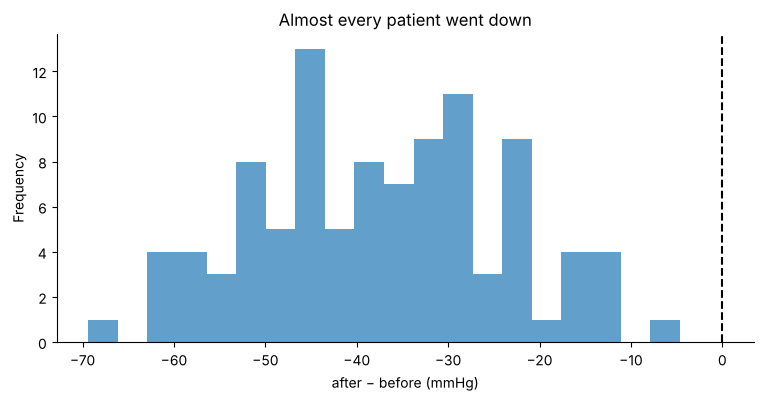

In [21]:
print("95% CI of the mean change:", np.round(stats.t.interval(0.95, df=len(bp) - 1,
                                                             loc=bp["diff"].mean(), scale=stats.sem(bp["diff"])), 1), "mmHg")
bp["diff"].plot(kind="hist", bins=20, alpha=0.7)
plt.axvline(0, color="black", ls="--"); plt.xlabel("after − before (mmHg)"); plt.title("Almost every patient went down"); plt.show()

✋ **Your turn (2'):** which test would you use for these questions?
1. Is the average sleep of Garmin users different from 7 hours?
2. Do users walk more on Saturdays than on Mondays? (the same users, measured on both days)
3. Is hitting the step goal related to the age group?

*Answers:* 1) one-sample t-test · 2) paired t-test · 3) χ² test (`stats.chi2_contingency`, Week 3).

---
## 6 · Errors and power 🎲 (10')

### 6.1 False alarms: run 2,000 experiments where H₀ is TRUE
Both groups come from the **same** population (sleep hours). Any "significant" result is a **Type I error**.

share with p < 0.05: 0.053   ← that is α!


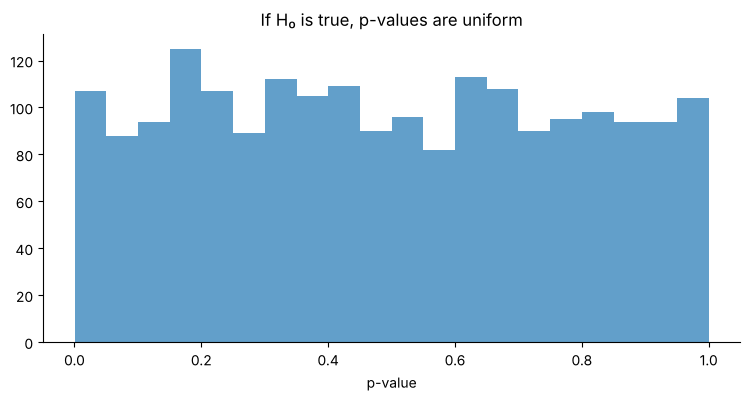

In [22]:
sleep = data["sleep_hours"].to_numpy()
p_values = np.array([
    stats.ttest_ind(rng.choice(sleep, 50), rng.choice(sleep, 50), equal_var=False).pvalue
    for _ in range(2_000)
])
print(f"share with p < 0.05: {np.mean(p_values < 0.05):.3f}   ← that is α!")
plt.hist(p_values, bins=20, alpha=0.7); plt.xlabel("p-value"); plt.title("If H₀ is true, p-values are uniform"); plt.show()

### 6.2 Power: a feature REALLY adds 10 minutes of sleep. How often do we detect it?
🧑‍💻 **Code with me:** simulate the experiment for different group sizes n and count how often p < 0.05.

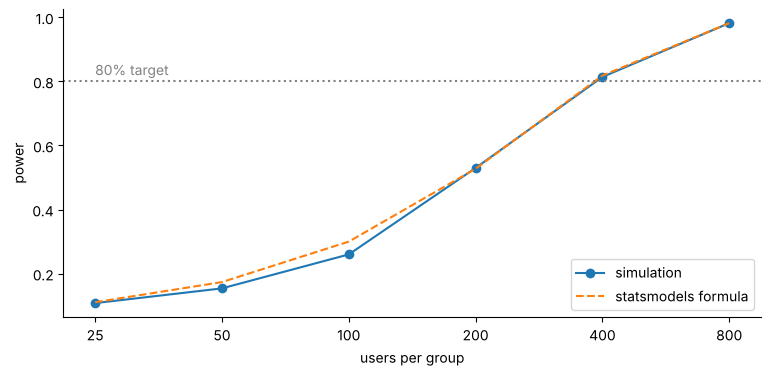

In [23]:
effect = 10 / 60          # +10 minutes, in hours
sizes = [25, 50, 100, 200, 400, 800]
power_sim = []
for n in sizes:
    hits = [stats.ttest_ind(rng.choice(sleep, n) + effect, rng.choice(sleep, n), equal_var=False).pvalue < 0.05
            for _ in range(500)]
    power_sim.append(np.mean(hits))

d = effect / sleep.std(ddof=1)                    # effect size in standard deviations (Cohen's d)
power_theory = [NormalIndPower().power(effect_size=d, nobs1=n, alpha=0.05) for n in sizes]

plt.plot(sizes, power_sim, "o-", label="simulation")
plt.plot(sizes, power_theory, "--", label="statsmodels formula")
plt.axhline(0.8, color="grey", ls=":"); plt.text(sizes[0], 0.82, "80% target", color="grey")
plt.xscale("log"); plt.minorticks_off(); plt.xticks(sizes, sizes)
plt.xlabel("users per group"); plt.ylabel("power"); plt.legend(); plt.show()

In [24]:
n_needed = NormalIndPower().solve_power(effect_size=d, alpha=0.05, power=0.8)
print(f"effect size d = {d:.2f} → we need about {np.ceil(n_needed):.0f} users per group for 80% power")

effect size d = 0.20 → we need about 382 users per group for 80% power


📌 With 50 users per group, a real 10-minute effect is missed most of the time. **Plan n before** the experiment.

---
## 7 · A/B testing end to end 🧪 (15')

### 7.1 Conversion test: does the new "Start workout" button work?
We simulate the test from the slides: 10,000 users per group, true conversion 10% (A) and 11% (B).

In [25]:
n_a = n_b = 10_000
conv_a = rng.random(n_a) < 0.10       # True = the user converted
conv_b = rng.random(n_b) < 0.11

counts = np.array([conv_b.sum(), conv_a.sum()])
nobs = np.array([n_b, n_a])
print(f"A: {conv_a.mean():.2%}   B: {conv_b.mean():.2%}   difference: {conv_b.mean() - conv_a.mean():+.2%}")

A: 9.91%   B: 10.62%   difference: +0.71%


🧑‍💻 **Code with me:** z-test for two proportions + 95% CI of the difference.

In [26]:
z, p = proportions_ztest(counts, nobs)
low, high = confint_proportions_2indep(counts[0], nobs[0], counts[1], nobs[1])   # CI for p_B − p_A
print(f"z = {z:.2f}, p = {p:.4f}")
print(f"95% CI of the difference: [{low:+.2%}, {high:+.2%}]")

z = 1.65, p = 0.0981
95% CI of the difference: [-0.13%, +1.55%]


### 7.2 Sample size *before* the test
How many users per group to detect 10% → 11% with 80% power?

In [27]:
h = proportion_effectsize(0.11, 0.10)                      # effect size for proportions
n_per_group = NormalIndPower().solve_power(effect_size=h, alpha=0.05, power=0.8)
print(f"about {np.ceil(n_per_group):,.0f} users per group   (rule of thumb from the slides: 14,400)")

about 14,745 users per group   (rule of thumb from the slides: 14,400)


### 7.3 ⚠️ The peeking problem
An **A/A test**: both groups are identical (10% each), so there is **nothing** to find. The analyst checks the p-value **every day for 20 days** (500 new users per group per day) and stops at the first p < 0.05.

In [28]:
def z_test_p(c1, n1, c2, n2):
    # two-sided p-value of the z-test for two proportions (vectorised)
    p_pool = (c1 + c2) / (n1 + n2)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    return 2 * stats.norm.sf(np.abs(c1 / n1 - c2 / n2) / se)

n_sims, days, per_day = 2_000, 20, 500
false_peek, false_once = 0, 0
for _ in range(n_sims):
    a = np.cumsum(rng.binomial(per_day, 0.10, size=days))      # cumulative conversions per day
    b = np.cumsum(rng.binomial(per_day, 0.10, size=days))
    n = per_day * np.arange(1, days + 1)
    p_daily = z_test_p(a, n, b, n)
    false_peek += np.any(p_daily < 0.05)        # stop at the first "win"
    false_once += p_daily[-1] < 0.05            # look only once, at the end

print(f"false positives, looking once at the end : {false_once / n_sims:.1%}")
print(f"false positives, peeking every day        : {false_peek / n_sims:.1%}")

false positives, looking once at the end : 6.9%
false positives, peeking every day        : 27.7%


📌 Peeking every day multiplies the false-positive rate. Fix the sample size first and analyse **once**.

### 7.4 A/B test on a mean: minutes spent on the page (`ab_test.csv`)
50 users saw version `a`, 50 users saw version `b`. Did version b keep users longer?

           a      b
count  50.00  50.00
mean    9.36  12.47
std     5.24   6.49
min     0.27   0.59
25%     5.42   8.11
50%     9.07  12.64
75%    13.46  17.85
max    20.90  24.00


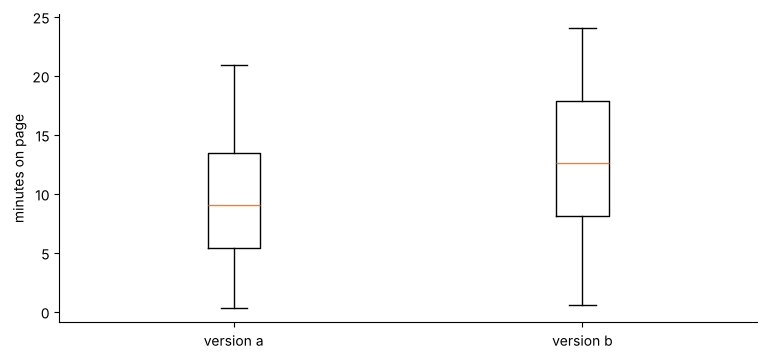

In [29]:
print(ab.describe().round(2))
plt.boxplot([ab["a"], ab["b"]], tick_labels=["version a", "version b"])
plt.ylabel("minutes on page"); plt.show()

In [30]:
res = stats.ttest_ind(ab["b"], ab["a"], equal_var=False)
diff = ab["b"].mean() - ab["a"].mean()
ci = res.confidence_interval(0.95)
print(f"difference = {diff:.2f} min, p = {res.pvalue:.4f}, 95% CI [{ci.low:.2f}, {ci.high:.2f}] min")

difference = 3.11 min, p = 0.0098, 95% CI [0.77, 5.45] min


✋ **Your turn (2'):** write one sentence for the product manager: what is the effect, how sure are we, and what would you recommend?

---
## 8 · Final challenge 🏁 (5')

The exercise from the slides: 800 users, B gets a sleep-coaching feature.
A: n = 400, mean 7.10 h, s = 0.8 · B: n = 400, mean 7.22 h, s = 0.8.

✋ **Your turn:** compute the test and the 95% CI of the difference with scipy, using only these summary numbers (hint: `stats.ttest_ind_from_stats`). Then translate the effect into minutes.

In [31]:
res = stats.ttest_ind_from_stats(mean1=7.22, std1=0.8, nobs1=400, mean2=7.10, std2=0.8, nobs2=400, equal_var=False)
diff = 7.22 - 7.10
se = np.sqrt(0.8**2 / 400 + 0.8**2 / 400)
print(f"t = {res.statistic:.2f}, p = {res.pvalue:.4f}")
print(f"95% CI: [{diff - 1.96 * se:.3f}, {diff + 1.96 * se:.3f}] h = [{(diff - 1.96 * se) * 60:.1f}, {(diff + 1.96 * se) * 60:.1f}] min")

t = 2.12, p = 0.0342
95% CI: [0.009, 0.231] h = [0.5, 13.9] min


*Answer:* significant at 5% (p ≈ 0.03), about **+7 minutes** of sleep, but plausibly anything between ~0.5 and ~14 minutes. Significant, small and uncertain → report the CI and let the business decide.

## 🧭 Recap

| Idea | Python |
|---|---|
| standard error | `stats.sem(x)` = `x.std(ddof=1) / np.sqrt(len(x))` |
| 95% CI for a mean | `stats.t.interval(0.95, df=n-1, loc=x.mean(), scale=stats.sem(x))` |
| one mean vs a value | `stats.ttest_1samp(x, value)` |
| two independent groups | `stats.ttest_ind(a, b, equal_var=False)` (Welch) |
| same units before / after | `stats.ttest_rel(after, before)` |
| two proportions | `proportions_ztest(counts, nobs)` + `confint_proportions_2indep(...)` |
| sample size / power | `NormalIndPower().solve_power(effect_size=..., alpha=0.05, power=0.8)` |

**Rules to remember:** random samples beat big samples · report effect size + CI, not only p · plan n before the test · never stop at the first p < 0.05.

🧪 **Saturday lab:** hypothesis testing (including `blood_pressure.csv`).